In [6]:
# Import required libraries
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

In [7]:
# Project 10: Quality Prediction in a Mining Process

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("Libraries imported successfully!")

Libraries imported successfully!


In [8]:
# Load the original mining flotation dataset

mining_raw = pd.read_csv("/content/MiningProcess_Flotation_Plant_Database.csv")

print("Dataset Shape:", mining_raw.shape)

print("\nDate range:")
print(mining_raw['date'].min(), "to", mining_raw['date'].max())

print("\nFirst 5 rows:")
display(mining_raw.head())

Dataset Shape: (737453, 24)

Date range:
2017-03-10 01:00:00 to 2017-09-09 23:00:00

First 5 rows:


,date,% Iron Feed,% Silica Feed,Starch Flow,Amina Flow,Ore Pulp Flow,Ore Pulp pH,Ore Pulp Density,Flotation Column 01 Air Flow,Flotation Column 02 Air Flow,...,Flotation Column 07 Air Flow,Flotation Column 01 Level,Flotation Column 02 Level,Flotation Column 03 Level,Flotation Column 04 Level,Flotation Column 05 Level,Flotation Column 06 Level,Flotation Column 07 Level,% Iron Concentrate,% Silica Concentrate
0,2017-03-10 01:00:00,"55,2","16,98","3019,53","557,434","395,713","10,0664","1,74","249,214","253,235",...,"250,884","457,396","432,962","424,954","443,558","502,255","446,37","523,344","66,91","1,31"
1,2017-03-10 01:00:00,"55,2","16,98","3024,41","563,965","397,383","10,0672","1,74","249,719","250,532",...,"248,994","451,891","429,56","432,939","448,086","496,363","445,922","498,075","66,91","1,31"
2,2017-03-10 01:00:00,"55,2","16,98","3043,46","568,054","399,668","10,068","1,74","249,741","247,874",...,"248,071","451,24","468,927","434,61","449,688","484,411","447,826","458,567","66,91","1,31"
3,2017-03-10 01:00:00,"55,2","16,98","3047,36","568,665","397,939","10,0689","1,74","249,917","254,487",...,"251,147","452,441","458,165","442,865","446,21","471,411","437,69","427,669","66,91","1,31"
4,2017-03-10 01:00:00,"55,2","16,98","3033,69","558,167","400,254","10,0697","1,74","250,203","252,136",...,"248,928","452,441","452,9","450,523","453,67","462,598","443,682","425,679","66,91","1,31"


In [9]:
# Convert date column
mining_clean = mining_raw.copy()

mining_clean['date'] = pd.to_datetime(
    mining_clean['date'],
    errors='coerce'
)

# Convert all other columns from comma-decimal strings to numeric
numeric_columns = mining_clean.columns.drop('date')

for col in numeric_columns:
    mining_clean[col] = pd.to_numeric(
        mining_clean[col].astype(str).str.replace(',', '.', regex=False),
        errors='coerce'
    )

# Check the cleaned dataset
print("Dataset Shape:", mining_clean.shape)

print("\nData Types:")
print(mining_clean.dtypes)

print("\nMissing Values:", mining_clean.isnull().sum().sum())

print("Duplicate Rows:", mining_clean.duplicated().sum())

Dataset Shape: (737453, 24)

Data Types:
date                            datetime64[ns]
% Iron Feed                            float64
% Silica Feed                          float64
Starch Flow                            float64
Amina Flow                             float64
Ore Pulp Flow                          float64
Ore Pulp pH                            float64
Ore Pulp Density                       float64
Flotation Column 01 Air Flow           float64
Flotation Column 02 Air Flow           float64
Flotation Column 03 Air Flow           float64
Flotation Column 04 Air Flow           float64
Flotation Column 05 Air Flow           float64
Flotation Column 06 Air Flow           float64
Flotation Column 07 Air Flow           float64
Flotation Column 01 Level              float64
Flotation Column 02 Level              float64
Flotation Column 03 Level              float64
Flotation Column 04 Level              float64
Flotation Column 05 Level              float64
Flotation Column 06

In [10]:
# Remove exact duplicate rows

before = len(mining_clean)

mining_clean = (
    mining_clean
    .drop_duplicates()
    .reset_index(drop=True)
)

after = len(mining_clean)

print("Duplicate rows removed:", before - after)
print("Cleaned dataset shape:", mining_clean.shape)

print("\nRemaining missing values:",
      mining_clean.isnull().sum().sum())

print("Remaining duplicate rows:",
      mining_clean.duplicated().sum())

Duplicate rows removed: 1171
Cleaned dataset shape: (736282, 24)

Remaining missing values: 0
Remaining duplicate rows: 0


In [11]:
# Check target statistics and time range

print("Date range:")
print(mining_clean['date'].min(), "to", mining_clean['date'].max())

print("\nUnique timestamps:")
print(mining_clean['date'].nunique())

print("\nTarget: % Silica Concentrate")
print(mining_clean['% Silica Concentrate'].describe())

print("\nTarget missing values:")
print(mining_clean['% Silica Concentrate'].isnull().sum())

Date range:
2017-03-10 01:00:00 to 2017-09-09 23:00:00

Unique timestamps:
4097

Target: % Silica Concentrate
count    736282.000000
mean          2.327270
std           1.125616
min           0.600000
25%           1.440000
50%           2.000000
75%           3.010000
max           5.530000
Name: % Silica Concentrate, dtype: float64

Target missing values:
0


In [12]:
# Sort the dataset chronologically
mining_clean = (
    mining_clean
    .sort_values('date')
    .reset_index(drop=True)
)

# 80% training, 20% validation
split_index = int(len(mining_clean) * 0.8)

mining_train = mining_clean.iloc[:split_index].copy()
mining_val = mining_clean.iloc[split_index:].copy()

print("Training shape:", mining_train.shape)
print("Validation shape:", mining_val.shape)

print("\nTraining period:")
print(
    mining_train['date'].min(),
    "to",
    mining_train['date'].max()
)

print("\nValidation period:")
print(
    mining_val['date'].min(),
    "to",
    mining_val['date'].max()
)

Training shape: (589025, 24)
Validation shape: (147257, 24)

Training period:
2017-03-10 01:00:00 to 2017-08-06 21:00:00

Validation period:
2017-08-06 21:00:00 to 2017-09-09 23:00:00


In [13]:
# Prepare baseline features

target = '% Silica Concentrate'

baseline_features = [
    col for col in mining_clean.columns
    if col not in ['date', target]
]

X_train_mining = mining_train[baseline_features]
y_train_mining = mining_train[target]

X_val_mining = mining_val[baseline_features]
y_val_mining = mining_val[target]

print("Number of features:", len(baseline_features))
print("\nFeatures:")
print(baseline_features)

print("\nX_train shape:", X_train_mining.shape)
print("X_val shape:", X_val_mining.shape)
print("y_train shape:", y_train_mining.shape)
print("y_val shape:", y_val_mining.shape)

Number of features: 22

Features:
['% Iron Feed', '% Silica Feed', 'Starch Flow', 'Amina Flow', 'Ore Pulp Flow', 'Ore Pulp pH', 'Ore Pulp Density', 'Flotation Column 01 Air Flow', 'Flotation Column 02 Air Flow', 'Flotation Column 03 Air Flow', 'Flotation Column 04 Air Flow', 'Flotation Column 05 Air Flow', 'Flotation Column 06 Air Flow', 'Flotation Column 07 Air Flow', 'Flotation Column 01 Level', 'Flotation Column 02 Level', 'Flotation Column 03 Level', 'Flotation Column 04 Level', 'Flotation Column 05 Level', 'Flotation Column 06 Level', 'Flotation Column 07 Level', '% Iron Concentrate']

X_train shape: (589025, 22)
X_val shape: (147257, 22)
y_train shape: (589025,)
y_val shape: (147257,)


In [14]:
# Baseline Random Forest

rf_baseline = RandomForestRegressor(
    n_estimators=30,
    max_depth=15,
    random_state=42,
    n_jobs=-1
)

print("Training baseline model...")

rf_baseline.fit(
    X_train_mining,
    y_train_mining
)

print("Baseline model training completed!")

Training baseline model...
Baseline model training completed!


In [15]:
# Make predictions
y_pred_baseline = rf_baseline.predict(X_val_mining)

# Calculate evaluation metrics
mae_baseline = mean_absolute_error(
    y_val_mining,
    y_pred_baseline
)

rmse_baseline = np.sqrt(
    mean_squared_error(
        y_val_mining,
        y_pred_baseline
    )
)

r2_baseline = r2_score(
    y_val_mining,
    y_pred_baseline
)

print("Baseline Random Forest Results")
print("--------------------------------")
print("MAE :", round(mae_baseline, 4))
print("RMSE:", round(rmse_baseline, 4))
print("R²  :", round(r2_baseline, 4))

Baseline Random Forest Results
--------------------------------
MAE : 0.6507
RMSE: 0.8254
R²  : 0.4813


In [16]:
# Remove % Iron Concentrate from the input features

features_no_iron = [
    col for col in baseline_features
    if col != '% Iron Concentrate'
]

X_train_no_iron = mining_train[features_no_iron]
X_val_no_iron = mining_val[features_no_iron]

print("Number of features without % Iron Concentrate:",
      len(features_no_iron))

print("X_train shape:", X_train_no_iron.shape)
print("X_val shape:", X_val_no_iron.shape)

Number of features without % Iron Concentrate: 21
X_train shape: (589025, 21)
X_val shape: (147257, 21)


In [17]:
# Random Forest without % Iron Concentrate

rf_no_iron = RandomForestRegressor(
    n_estimators=30,
    max_depth=15,
    random_state=42,
    n_jobs=-1
)

print("Training model without % Iron Concentrate...")

rf_no_iron.fit(
    X_train_no_iron,
    y_train_mining
)

print("Model training completed!")

Training model without % Iron Concentrate...
Model training completed!


In [18]:
# Make predictions
y_pred_no_iron = rf_no_iron.predict(X_val_no_iron)

# Calculate evaluation metrics
mae_no_iron = mean_absolute_error(
    y_val_mining,
    y_pred_no_iron
)

rmse_no_iron = np.sqrt(
    mean_squared_error(
        y_val_mining,
        y_pred_no_iron
    )
)

r2_no_iron = r2_score(
    y_val_mining,
    y_pred_no_iron
)

# Display results
print("Random Forest Without % Iron Concentrate Results")
print("------------------------------------------------")
print("MAE :", round(mae_no_iron, 4))
print("RMSE:", round(rmse_no_iron, 4))
print("R²  :", round(r2_no_iron, 4))

Random Forest Without % Iron Concentrate Results
------------------------------------------------
MAE : 0.9804
RMSE: 1.2418
R²  : -0.1742


In [19]:
# Feature importance from baseline Random Forest

importance_mining = pd.DataFrame({
    'Feature': baseline_features,
    'Importance': rf_baseline.feature_importances_
})

importance_mining = importance_mining.sort_values(
    by='Importance',
    ascending=False
)

print("Feature Importance:")
display(importance_mining)

Feature Importance:


,Feature,Importance
21,% Iron Concentrate,0.762904
1,% Silica Feed,0.046892
0,% Iron Feed,0.032552
16,Flotation Column 03 Level,0.021432
5,Ore Pulp pH,0.018646
3,Amina Flow,0.016005
7,Flotation Column 01 Air Flow,0.014305
6,Ore Pulp Density,0.011982
10,Flotation Column 04 Air Flow,0.011488
14,Flotation Column 01 Level,0.010471


In [20]:
# Week 3 - Project 10: Check model variables

print("Training data:", mining_train.shape)
print("Validation data:", mining_val.shape)

print("Actual validation values:", len(y_val_mining))
print("Baseline predictions:", len(y_pred_baseline))

print("\nBaseline model metrics:")
print("MAE:", round(mae_baseline, 4))
print("RMSE:", round(rmse_baseline, 4))
print("R²:", round(r2_baseline, 4))

Training data: (589025, 24)
Validation data: (147257, 24)
Actual validation values: 147257
Baseline predictions: 147257

Baseline model metrics:
MAE: 0.6507
RMSE: 0.8254
R²: 0.4813


In [21]:
# Week 3 - Project 10: Residual Analysis

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Actual and predicted silica concentration
actual_mining = np.asarray(y_val_mining)
predicted_mining = np.asarray(y_pred_baseline)

# Calculate residuals
residuals_mining = actual_mining - predicted_mining

print("Residual Analysis - Mining Process")
print("----------------------------------")
print("Mean Residual:",
      round(np.mean(residuals_mining), 4))
print("Mean Absolute Error:",
      round(np.mean(np.abs(residuals_mining)), 4))
print("Maximum Absolute Error:",
      round(np.max(np.abs(residuals_mining)), 4))
print("Minimum Residual:",
      round(np.min(residuals_mining), 4))
print("Maximum Residual:",
      round(np.max(residuals_mining), 4))

Residual Analysis - Mining Process
----------------------------------
Mean Residual: -0.3101
Mean Absolute Error: 0.6507
Maximum Absolute Error: 3.0832
Minimum Residual: -3.0832
Maximum Residual: 2.6622


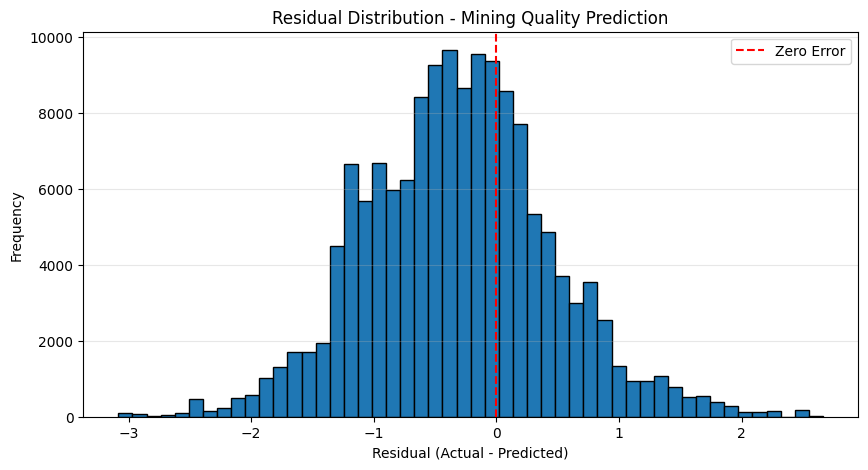

In [22]:
# Week 3 - Project 10: Residual Distribution

plt.figure(figsize=(10, 5))

plt.hist(
    residuals_mining,
    bins=50,
    edgecolor='black'
)

plt.axvline(
    0,
    color='red',
    linestyle='--',
    label='Zero Error'
)

plt.xlabel("Residual (Actual - Predicted)")
plt.ylabel("Frequency")
plt.title("Residual Distribution - Mining Quality Prediction")
plt.legend()
plt.grid(axis='y', alpha=0.3)
plt.show()

In [23]:
# Week 3 - Project 10: Largest prediction errors

error_analysis_mining = pd.DataFrame({
    'Actual_Silica': actual_mining,
    'Predicted_Silica': predicted_mining,
    'Residual': residuals_mining,
    'Absolute_Error': np.abs(residuals_mining)
})

# Add timestamps from the validation dataset
error_analysis_mining['Date'] = (
    mining_val['date'].to_numpy()
)

largest_errors_mining = (
    error_analysis_mining
    .sort_values('Absolute_Error', ascending=False)
    .head(10)
)

display(largest_errors_mining.round(4))

,Actual_Silica,Predicted_Silica,Residual,Absolute_Error,Date
69073,1.37,4.4532,-3.0832,3.0832,2017-08-22 21:00:00
69081,1.37,4.4319,-3.0619,3.0619,2017-08-22 21:00:00
69058,1.37,4.4305,-3.0605,3.0605,2017-08-22 21:00:00
69125,1.37,4.4259,-3.0559,3.0559,2017-08-22 21:00:00
69056,1.37,4.4190,-3.0490,3.0490,2017-08-22 21:00:00
69089,1.37,4.4165,-3.0465,3.0465,2017-08-22 21:00:00
69133,1.37,4.4157,-3.0457,3.0457,2017-08-22 21:00:00
69080,1.37,4.4156,-3.0456,3.0456,2017-08-22 21:00:00
69079,1.37,4.4156,-3.0456,3.0456,2017-08-22 21:00:00
69078,1.37,4.4148,-3.0448,3.0448,2017-08-22 21:00:00


In [24]:
# Week 3 - Project 10: Error analysis by date

error_analysis_mining['Date'] = pd.to_datetime(
    error_analysis_mining['Date']
)

error_analysis_mining['DateOnly'] = (
    error_analysis_mining['Date'].dt.date
)

daily_errors = (
    error_analysis_mining
    .groupby('DateOnly')
    .agg(
        Observations=('Absolute_Error', 'size'),
        MAE=('Absolute_Error', 'mean'),
        Mean_Residual=('Residual', 'mean'),
        Maximum_Error=('Absolute_Error', 'max')
    )
    .reset_index()
)

print("Dates with the highest MAE:")
display(
    daily_errors
    .sort_values('MAE', ascending=False)
    .head(10)
    .round(4)
)

Dates with the highest MAE:


,DateOnly,Observations,MAE,Mean_Residual,Maximum_Error
11,2017-08-17,4320,1.1907,-1.1907,1.5335
26,2017-09-01,4320,0.9199,-0.0913,2.5523
1,2017-08-07,4320,0.8613,-0.8612,2.4984
13,2017-08-19,4320,0.8143,0.4365,2.3943
22,2017-08-28,4320,0.8134,-0.0026,2.6622
24,2017-08-30,4320,0.8023,0.6278,1.8533
29,2017-09-04,4320,0.7794,-0.3256,2.4272
17,2017-08-23,4320,0.7754,-0.7032,2.8709
3,2017-08-09,4320,0.7726,-0.4983,2.4890
27,2017-09-02,4320,0.7700,-0.2712,2.2490


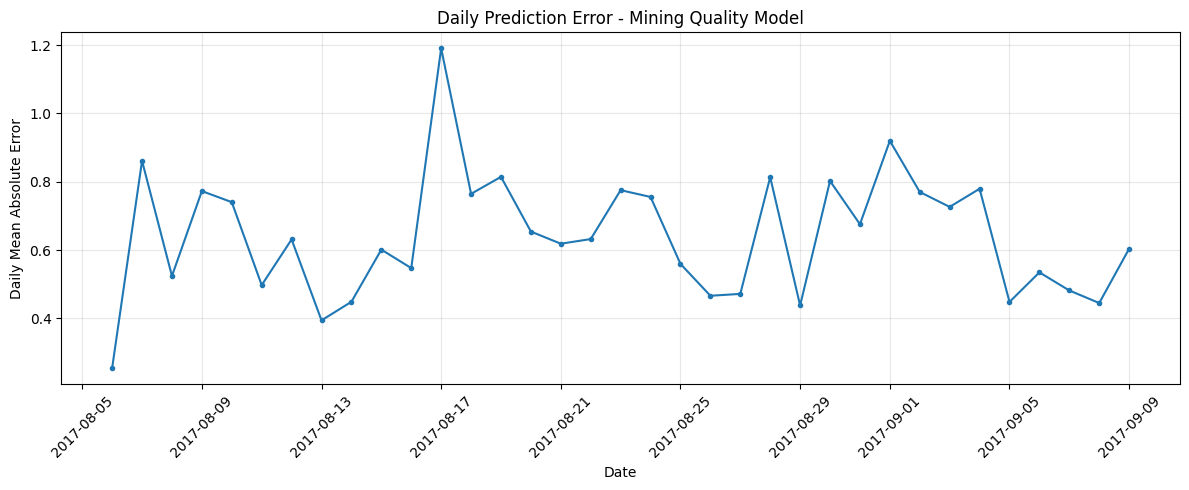

In [25]:
# Week 3 - Project 10: Daily MAE trend

daily_errors['DateOnly'] = pd.to_datetime(
    daily_errors['DateOnly']
)

daily_errors = daily_errors.sort_values('DateOnly')

plt.figure(figsize=(12, 5))

plt.plot(
    daily_errors['DateOnly'],
    daily_errors['MAE'],
    marker='o',
    markersize=3
)

plt.xlabel("Date")
plt.ylabel("Daily Mean Absolute Error")
plt.title("Daily Prediction Error - Mining Quality Model")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [26]:
# Week 3 - Project 10: Compare model performance

comparison_mining = pd.DataFrame({
    'Model': [
        'Random Forest with % Iron Concentrate',
        'Random Forest without % Iron Concentrate'
    ],
    'MAE': [
        mae_baseline,
        mae_no_iron
    ],
    'RMSE': [
        rmse_baseline,
        rmse_no_iron
    ],
    'R2': [
        r2_baseline,
        r2_no_iron
    ]
})

display(comparison_mining.round(4))

,Model,MAE,RMSE,R2
0,Random Forest with % Iron Concentrate,0.6507,0.8254,0.4813
1,Random Forest without % Iron Concentrate,0.9804,1.2418,-0.1742


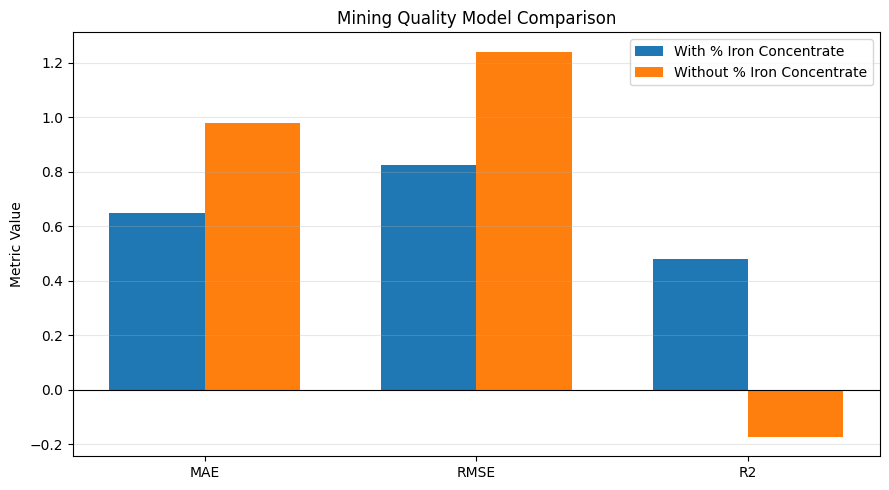

In [27]:
# Week 3 - Project 10: Model comparison chart

metrics = ['MAE', 'RMSE', 'R2']

with_iron = [
    mae_baseline,
    rmse_baseline,
    r2_baseline
]

without_iron = [
    mae_no_iron,
    rmse_no_iron,
    r2_no_iron
]

x = np.arange(len(metrics))
width = 0.35

plt.figure(figsize=(9, 5))

plt.bar(
    x - width / 2,
    with_iron,
    width,
    label='With % Iron Concentrate'
)

plt.bar(
    x + width / 2,
    without_iron,
    width,
    label='Without % Iron Concentrate'
)

plt.axhline(0, color='black', linewidth=0.8)
plt.xticks(x, metrics)
plt.ylabel('Metric Value')
plt.title('Mining Quality Model Comparison')
plt.legend()
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

In [28]:
# Week 3 - Project 10: Extra Trees experiment

from sklearn.ensemble import ExtraTreesRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import numpy as np

extra_trees = ExtraTreesRegressor(
    n_estimators=50,
    max_depth=15,
    random_state=42,
    n_jobs=-1
)

print("Training Extra Trees model...")

extra_trees.fit(X_train_mining, y_train_mining)

print("Training completed.")

# Predict on the same validation set
y_pred_extra = extra_trees.predict(X_val_mining)

# Evaluate
mae_extra = mean_absolute_error(
    y_val_mining, y_pred_extra
)

rmse_extra = np.sqrt(
    mean_squared_error(y_val_mining, y_pred_extra)
)

r2_extra = r2_score(
    y_val_mining, y_pred_extra
)

print("\nExtra Trees Results")
print("-------------------")
print("MAE:", round(mae_extra, 4))
print("RMSE:", round(rmse_extra, 4))
print("R2:", round(r2_extra, 4))

Training Extra Trees model...
Training completed.

Extra Trees Results
-------------------
MAE: 0.5726
RMSE: 0.7157
R2: 0.61


In [29]:
# Week 3 - Project 10: Final model comparison

final_comparison_mining = pd.DataFrame({
    'Model': [
        'Random Forest (All Features)',
        'Random Forest (Without Iron)',
        'Extra Trees (All Features)'
    ],
    'MAE': [
        mae_baseline,
        mae_no_iron,
        mae_extra
    ],
    'RMSE': [
        rmse_baseline,
        rmse_no_iron,
        rmse_extra
    ],
    'R2': [
        r2_baseline,
        r2_no_iron,
        r2_extra
    ]
})

display(
    final_comparison_mining
    .sort_values('MAE')
    .round(4)
    .reset_index(drop=True)
)

,Model,MAE,RMSE,R2
0,Extra Trees (All Features),0.5726,0.7157,0.6100
1,Random Forest (All Features),0.6507,0.8254,0.4813
2,Random Forest (Without Iron),0.9804,1.2418,-0.1742


Extra Trees Residual Analysis
-----------------------------
Mean Residual: -0.3179
MAE: 0.5726
Maximum Absolute Error: 2.5119
Minimum Residual: -2.4457
Maximum Residual: 2.5119


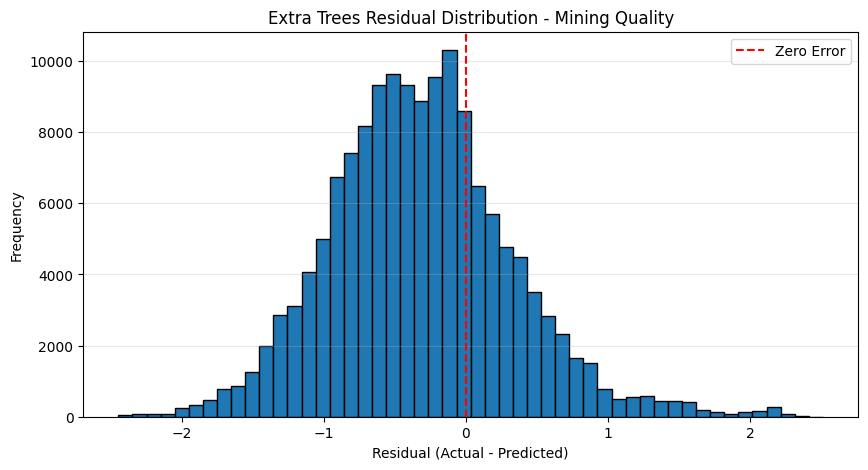

In [30]:
# Week 3 - Project 10: Extra Trees residual analysis

residuals_extra = (
    np.asarray(y_val_mining) -
    np.asarray(y_pred_extra)
)

print("Extra Trees Residual Analysis")
print("-----------------------------")
print("Mean Residual:",
      round(np.mean(residuals_extra), 4))
print("MAE:",
      round(mean_absolute_error(y_val_mining, y_pred_extra), 4))
print("Maximum Absolute Error:",
      round(np.max(np.abs(residuals_extra)), 4))
print("Minimum Residual:",
      round(np.min(residuals_extra), 4))
print("Maximum Residual:",
      round(np.max(residuals_extra), 4))

plt.figure(figsize=(10, 5))

plt.hist(
    residuals_extra,
    bins=50,
    edgecolor='black'
)

plt.axvline(
    0,
    color='red',
    linestyle='--',
    label='Zero Error'
)

plt.xlabel("Residual (Actual - Predicted)")
plt.ylabel("Frequency")
plt.title("Extra Trees Residual Distribution - Mining Quality")
plt.legend()
plt.grid(axis='y', alpha=0.3)
plt.show()

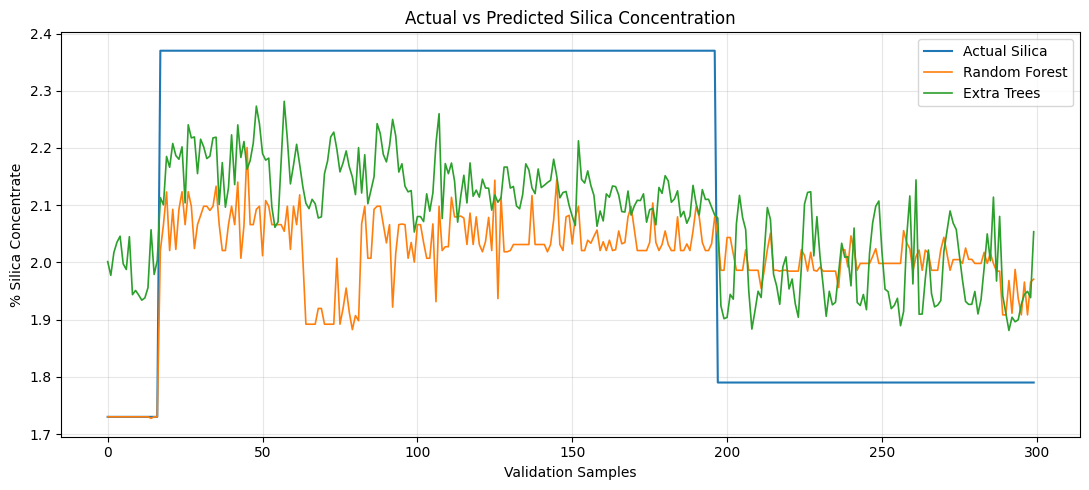

In [31]:
# Week 3 - Project 10: Actual vs Predicted
# Compare the first 300 validation observations

plt.figure(figsize=(11, 5))

plt.plot(
    np.asarray(y_val_mining)[:300],
    label='Actual Silica',
    linewidth=1.5
)

plt.plot(
    y_pred_baseline[:300],
    label='Random Forest',
    linewidth=1.2
)

plt.plot(
    y_pred_extra[:300],
    label='Extra Trees',
    linewidth=1.2
)

plt.xlabel("Validation Samples")
plt.ylabel("% Silica Concentrate")
plt.title("Actual vs Predicted Silica Concentration")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [32]:
# Check actual and predicted values for the first 300 samples

comparison_check = pd.DataFrame({
    "Actual": np.asarray(y_val_mining)[:300],
    "Random_Forest": np.asarray(y_pred_baseline)[:300],
    "Extra_Trees": np.asarray(y_pred_extra)[:300]
})

print("First 20 validation observations:")
display(comparison_check.head(20).round(4))

print("\nUnique actual values in first 300 samples:",
      comparison_check["Actual"].nunique())

print("\nActual value frequencies:")
print(comparison_check["Actual"].value_counts().head(10))

First 20 validation observations:


,Actual,Random_Forest,Extra_Trees
0,1.73,1.7301,2.0014
1,1.73,1.7301,1.9773
2,1.73,1.7301,2.0174
3,1.73,1.7301,2.0353
4,1.73,1.7301,2.0458
5,1.73,1.7301,1.9976
6,1.73,1.7301,1.9875
7,1.73,1.7301,2.0450
8,1.73,1.7301,1.9436
9,1.73,1.7301,1.9510



Unique actual values in first 300 samples: 3

Actual value frequencies:
Actual
2.37    180
1.79    103
1.73     17
Name: count, dtype: int64


In [33]:
# Week 3 - Check actual silica variation

print("First 20 validation timestamps and targets:")

display(
    mining_val[['date', '% Silica Concentrate']]
    .head(20)
)

print("\nNumber of unique target values in validation set:")
print(y_val_mining.nunique())

print("\nMost frequent target values in validation set:")
print(y_val_mining.value_counts().head(10))

First 20 validation timestamps and targets:


,date,% Silica Concentrate
589025,2017-08-06 21:00:00,1.73
589026,2017-08-06 21:00:00,1.73
589027,2017-08-06 21:00:00,1.73
589028,2017-08-06 21:00:00,1.73
589029,2017-08-06 21:00:00,1.73
589030,2017-08-06 21:00:00,1.73
589031,2017-08-06 21:00:00,1.73
589032,2017-08-06 21:00:00,1.73
589033,2017-08-06 21:00:00,1.73
589034,2017-08-06 21:00:00,1.73



Number of unique target values in validation set:
13063

Most frequent target values in validation set:
% Silica Concentrate
1.19    5400
2.21    2700
1.25    2160
1.79    1620
1.21    1620
1.42    1620
1.26    1620
1.35    1440
1.59    1440
1.41    1440
Name: count, dtype: int64


In [34]:
variables_to_check = [
    'mining_clean',
    'mining_train',
    'mining_val',
    'X_train',
    'X_val',
    'y_train',
    'y_val',
    'rf_model',
    'extra_trees',
    'y_pred',
    'y_pred_et'
]

for name in variables_to_check:
    if name in globals():
        obj = globals()[name]
        print(f"✓ {name}: {getattr(obj, 'shape', 'Available')}")
    else:
        print(f"✗ {name}: Not found")

✓ mining_clean: (736282, 24)
✓ mining_train: (589025, 24)
✓ mining_val: (147257, 24)
✗ X_train: Not found
✗ X_val: Not found
✗ y_train: Not found
✗ y_val: Not found
✗ rf_model: Not found
✓ extra_trees: Available
✗ y_pred: Not found
✗ y_pred_et: Not found


In [35]:
print("Dataset columns:")
print(mining_clean.columns.tolist())

print("\nExtra Trees model:")
print(extra_trees)

print("\nAvailable model-related variables:")

for name, obj in globals().copy().items():
    if 'model' in name.lower() or 'tree' in name.lower() or 'pred' in name.lower():
        if not name.startswith('_'):
            print(name, type(obj).__name__)

Dataset columns:
['date', '% Iron Feed', '% Silica Feed', 'Starch Flow', 'Amina Flow', 'Ore Pulp Flow', 'Ore Pulp pH', 'Ore Pulp Density', 'Flotation Column 01 Air Flow', 'Flotation Column 02 Air Flow', 'Flotation Column 03 Air Flow', 'Flotation Column 04 Air Flow', 'Flotation Column 05 Air Flow', 'Flotation Column 06 Air Flow', 'Flotation Column 07 Air Flow', 'Flotation Column 01 Level', 'Flotation Column 02 Level', 'Flotation Column 03 Level', 'Flotation Column 04 Level', 'Flotation Column 05 Level', 'Flotation Column 06 Level', 'Flotation Column 07 Level', '% Iron Concentrate', '% Silica Concentrate']

Extra Trees model:
ExtraTreesRegressor(max_depth=15, n_estimators=50, n_jobs=-1, random_state=42)

Available model-related variables:
y_pred_baseline ndarray
y_pred_no_iron ndarray
predicted_mining ndarray
ExtraTreesRegressor ABCMeta
extra_trees ExtraTreesRegressor
y_pred_extra ndarray


In [36]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Separate actual target values from validation data
y_val_mining = mining_val['% Silica Concentrate']

# Evaluate existing Extra Trees predictions
print("Validation rows:", len(mining_val))
print("Prediction count:", len(y_pred_extra))

print("\nExtra Trees Performance:")
print("MAE:", mean_absolute_error(y_val_mining, y_pred_extra))
print("RMSE:", np.sqrt(mean_squared_error(y_val_mining, y_pred_extra)))
print("R² Score:", r2_score(y_val_mining, y_pred_extra))

Validation rows: 147257
Prediction count: 147257

Extra Trees Performance:
MAE: 0.5725969640770235
RMSE: 0.7156526277871638
R² Score: 0.6100358533774237


In [37]:
print("Number of input features:", len(extra_trees.feature_names_in_))

print("\nFeatures used by Extra Trees:")
for i, feature in enumerate(extra_trees.feature_names_in_, 1):
    print(f"{i}. {feature}")

print("\nTarget variable: % Silica Concentrate")

Number of input features: 22

Features used by Extra Trees:
1. % Iron Feed
2. % Silica Feed
3. Starch Flow
4. Amina Flow
5. Ore Pulp Flow
6. Ore Pulp pH
7. Ore Pulp Density
8. Flotation Column 01 Air Flow
9. Flotation Column 02 Air Flow
10. Flotation Column 03 Air Flow
11. Flotation Column 04 Air Flow
12. Flotation Column 05 Air Flow
13. Flotation Column 06 Air Flow
14. Flotation Column 07 Air Flow
15. Flotation Column 01 Level
16. Flotation Column 02 Level
17. Flotation Column 03 Level
18. Flotation Column 04 Level
19. Flotation Column 05 Level
20. Flotation Column 06 Level
21. Flotation Column 07 Level
22. % Iron Concentrate

Target variable: % Silica Concentrate


Top 10 Important Features:


,Feature,Importance
21,% Iron Concentrate,0.745912
0,% Iron Feed,0.033644
1,% Silica Feed,0.032992
7,Flotation Column 01 Air Flow,0.018313
9,Flotation Column 03 Air Flow,0.018170
5,Ore Pulp pH,0.016429
16,Flotation Column 03 Level,0.016266
10,Flotation Column 04 Air Flow,0.014357
6,Ore Pulp Density,0.013773
3,Amina Flow,0.013434


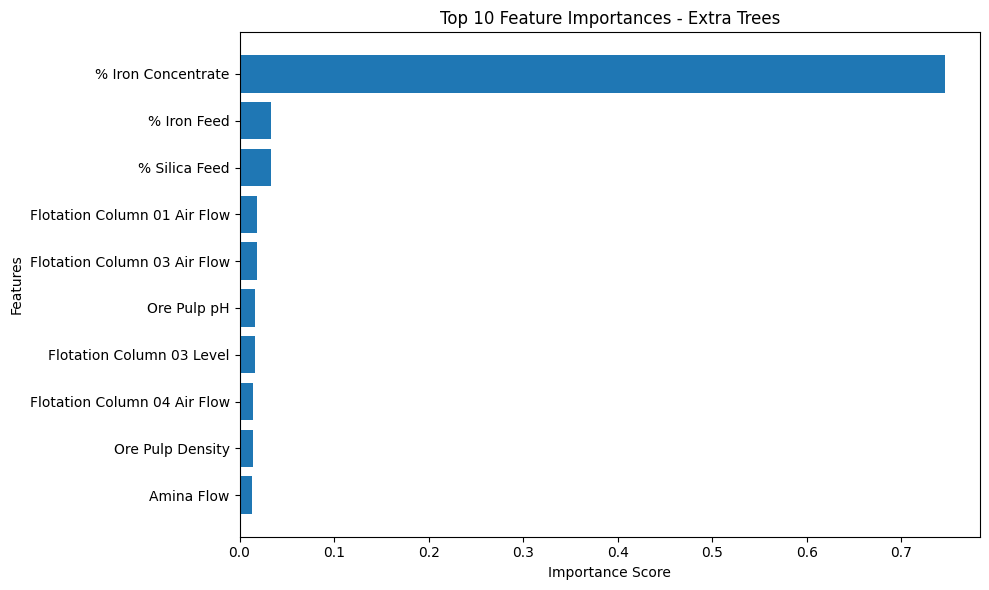

In [38]:
import pandas as pd

feature_importance = pd.DataFrame({
    'Feature': extra_trees.feature_names_in_,
    'Importance': extra_trees.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by='Importance', ascending=False
)

print("Top 10 Important Features:")
display(feature_importance.head(10))

# Plot feature importance
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
plt.barh(
    feature_importance.head(10)['Feature'][::-1],
    feature_importance.head(10)['Importance'][::-1]
)
plt.xlabel("Importance Score")
plt.ylabel("Features")
plt.title("Top 10 Feature Importances - Extra Trees")
plt.tight_layout()
plt.show()

In [39]:
print("Available Project 10 analysis variables:\n")

for name, obj in globals().copy().items():
    if any(word in name.lower() for word in [
        'residual', 'error', 'actual', 'pred', 'daily', 'comparison'
    ]):
        if not name.startswith('_'):
            print(f"{name}: {type(obj).__name__}")

Available Project 10 analysis variables:

mean_absolute_error: function
mean_squared_error: function
y_pred_baseline: ndarray
y_pred_no_iron: ndarray
actual_mining: ndarray
predicted_mining: ndarray
residuals_mining: ndarray
error_analysis_mining: DataFrame
largest_errors_mining: DataFrame
daily_errors: DataFrame
comparison_mining: DataFrame
y_pred_extra: ndarray
final_comparison_mining: DataFrame
residuals_extra: ndarray
comparison_check: DataFrame


In [40]:
print("Final Model Comparison:")
display(final_comparison_mining)

print("\nComparison Verification:")
display(comparison_check)

print("\nExtra Trees Residual Statistics:")
print("Mean residual:", residuals_extra.mean())
print("MAE:", mean_absolute_error(actual_mining, predicted_mining))

Final Model Comparison:


,Model,MAE,RMSE,R2
0,Random Forest (All Features),0.650662,0.825351,0.481323
1,Random Forest (Without Iron),0.980410,1.241821,-0.174190
2,Extra Trees (All Features),0.572597,0.715653,0.610036



Comparison Verification:


,Actual,Random_Forest,Extra_Trees
0,1.73,1.730056,2.001370
1,1.73,1.730056,1.977305
2,1.73,1.730056,2.017378
3,1.73,1.730056,2.035301
4,1.73,1.730056,2.045782
...,...,...,...
295,1.79,1.908246,1.926534
296,1.79,1.965579,1.943940
297,1.79,1.908246,1.949324
298,1.79,1.965579,1.938381



Extra Trees Residual Statistics:
Mean residual: -0.31792905371952673
MAE: 0.6506616026259847


In [41]:
# Correct Extra Trees evaluation
mae_extra = mean_absolute_error(actual_mining, y_pred_extra)
rmse_extra = np.sqrt(mean_squared_error(actual_mining, y_pred_extra))
r2_extra = r2_score(actual_mining, y_pred_extra)

print("Correct Extra Trees Results")
print("MAE:", mae_extra)
print("RMSE:", rmse_extra)
print("R²:", r2_extra)

print("\nResidual Statistics")
print("Mean residual:", residuals_extra.mean())
print("Mean absolute residual:", np.abs(residuals_extra).mean())
print("Maximum absolute residual:", np.abs(residuals_extra).max())

Correct Extra Trees Results
MAE: 0.5725969640770235
RMSE: 0.7156526277871638
R²: 0.6100358533774237

Residual Statistics
Mean residual: -0.31792905371952673
Mean absolute residual: 0.5725969640770235
Maximum absolute residual: 2.5118912578494292
